# Isolation Forest

**Objective:** Detect rare transactions in the Credit Card Fraud Detection dataset using a full-dimensional Isolation Forest and a separate 2D PCA visualization layer.



In [1]:

from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, precision_recall_curve

warnings.filterwarnings("ignore")


PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.anomaly_detection.metrics import evaluate_binary_predictions, select_percentile_threshold
from src.anomaly_detection.visualization import configure_plot_style, save_figure

configure_plot_style()
RANDOM_STATE = 42
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [2]:

DATA_PATH = PROJECT_ROOT / "data" / "creditcard.csv"
TARGET = "Class"
CONTAMINATION_CANDIDATES = [0.001, 0.005, 0.01, 0.02]
N_ESTIMATORS_CANDIDATES = [200, 400]
MAX_SAMPLE = "auto"


EXPERIMENT = {
    "random_state": RANDOM_STATE,
    "contamination_candidates": CONTAMINATION_CANDIDATES,
    "n_estimators_candidates": N_ESTIMATORS_CANDIDATES,
    "max_samples": MAX_SAMPLE,
}
EXPERIMENT

{'random_state': 42,
 'contamination_candidates': [0.001, 0.005, 0.01, 0.02],
 'n_estimators_candidates': [200, 400],
 'max_samples': 'auto'}

In [3]:
from sklearn.ensemble import IsolationForest

# Load and validate schema.
df = pd.read_csv(DATA_PATH)
if TARGET not in df.columns:
    raise ValueError(f"Expected target column {TARGET!r}. Found: {list(df.columns)[:10]}...")

# Separate target and features. Credit Card Fraud has Time, V1..V28, Amount, Class.
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

# Numeric-only matrix
X = X.select_dtypes(include=np.number).copy()
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))

# Robust scaling is useful for monetary variables with heavy tails.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
scaler = RobustScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Train shape: {X_train_s.shape}; test shape: {X_test_s.shape}")
print(f"Fraud prevalence in test set: {y_test.mean():.4%}")

Train shape: (213605, 30); test shape: (71202, 30)
Fraud prevalence in test set: 0.1727%


In [4]:
# Tune hyperparameters using a labeled validation slice only for model selection.
# The detector itself remains unsupervised: y is never used during fit().
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_s, y_train, test_size=0.20, stratify=y_train, random_state=RANDOM_STATE
)

results = []
for params in ParameterGrid({
    "contamination": CONTAMINATION_CANDIDATES,
    "n_estimators": N_ESTIMATORS_CANDIDATES,
}):
    model = IsolationForest(
        random_state=RANDOM_STATE,
        n_jobs=-1,
        max_samples=MAX_SAMPLE,
        **params,
    )
    model.fit(X_fit)
    # score_samples is higher for more normal points, so invert it for anomaly score.
    val_scores = -model.score_samples(X_val)
    val_pred = (model.predict(X_val) == -1).astype(int)
    results.append({
        **params,
        "pr_auc": average_precision_score(y_val, val_scores),
        "precision": evaluate_binary_predictions(y_val, val_pred, val_scores).precision,
        "recall": evaluate_binary_predictions(y_val, val_pred, val_scores).recall,
        "f1": evaluate_binary_predictions(y_val, val_pred, val_scores).f1,
    })

results_df = pd.DataFrame(results).sort_values("pr_auc", ascending=False)
results_df

,contamination,n_estimators,pr_auc,precision,recall,f1
1,0.001,400,0.111756,0.234043,0.148649,0.181818
3,0.005,400,0.111756,0.142202,0.418919,0.212329
7,0.020,400,0.111756,0.055556,0.648649,0.102345
5,0.010,400,0.111756,0.096244,0.554054,0.164000
2,0.005,200,0.088821,0.117647,0.351351,0.176271
0,0.001,200,0.088821,0.133333,0.081081,0.100840
4,0.010,200,0.088821,0.092199,0.527027,0.156942
6,0.020,200,0.088821,0.054795,0.648649,0.101053


In [5]:
best_params = results_df.iloc[0][["contamination", "n_estimators"]].to_dict()
best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["contamination"] = float(best_params["contamination"])

model = IsolationForest(
    random_state=RANDOM_STATE,
    n_jobs=-1,
    max_samples=MAX_SAMPLE,
    **best_params,
)
start = time.perf_counter()
model.fit(X_train_s)
fit_seconds = time.perf_counter() - start

test_scores = -model.score_samples(X_test_s)
test_pred = (model.predict(X_test_s) == -1).astype(int)
metrics = evaluate_binary_predictions(y_test, test_pred, test_scores)

print("Best parameters:", best_params)
print(f"Fit time: {fit_seconds:.3f}s")
print(metrics)

Best parameters: {'contamination': 0.001, 'n_estimators': 400}
Fit time: 9.702s
EvaluationResult(precision=0.37142857142857144, recall=0.21138211382113822, f1=0.2694300518134715, pr_auc=0.1875346303643732, roc_auc=0.9501013243365879)


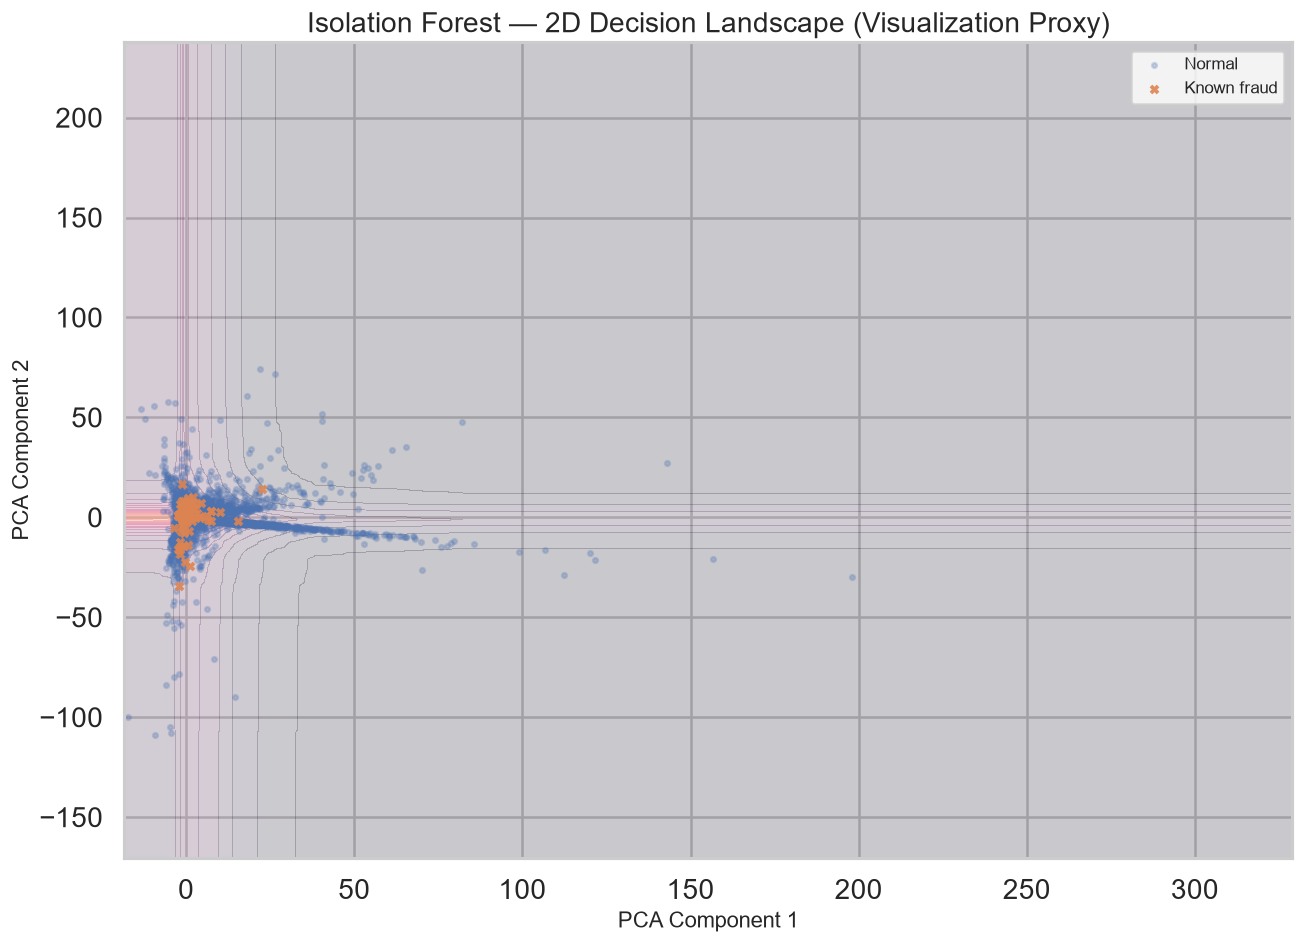

In [6]:
# 2D decision-boundary visualization.
# This is a visualization-only proxy model trained on the first two PCA coordinates.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d = pca.transform(X_test_s)

viz_model = IsolationForest(
    random_state=RANDOM_STATE,
    contamination=best_params["contamination"],
    n_estimators=best_params["n_estimators"],
)
viz_model.fit(X_train_2d)

pad = 1.0
x_min, x_max = X_train_2d[:, 0].min() - pad, X_train_2d[:, 0].max() + pad
y_min, y_max = X_train_2d[:, 1].min() - pad, X_train_2d[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
zz = viz_model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(11, 8))
ax.contourf(xx, yy, zz, levels=30, alpha=0.22)
anom = y_test.to_numpy() == 1
ax.scatter(X_test_2d[~anom, 0], X_test_2d[~anom, 1], s=8, alpha=0.25, label="Normal")
ax.scatter(X_test_2d[anom, 0], X_test_2d[anom, 1], s=18, alpha=0.9, marker="x", label="Known fraud")
ax.set_title("Isolation Forest — 2D Decision Landscape (Visualization Proxy)")
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.legend()
fig.tight_layout()
save_figure(fig, FIG_DIR / "isolation_forest_decision_boundary")
plt.show()

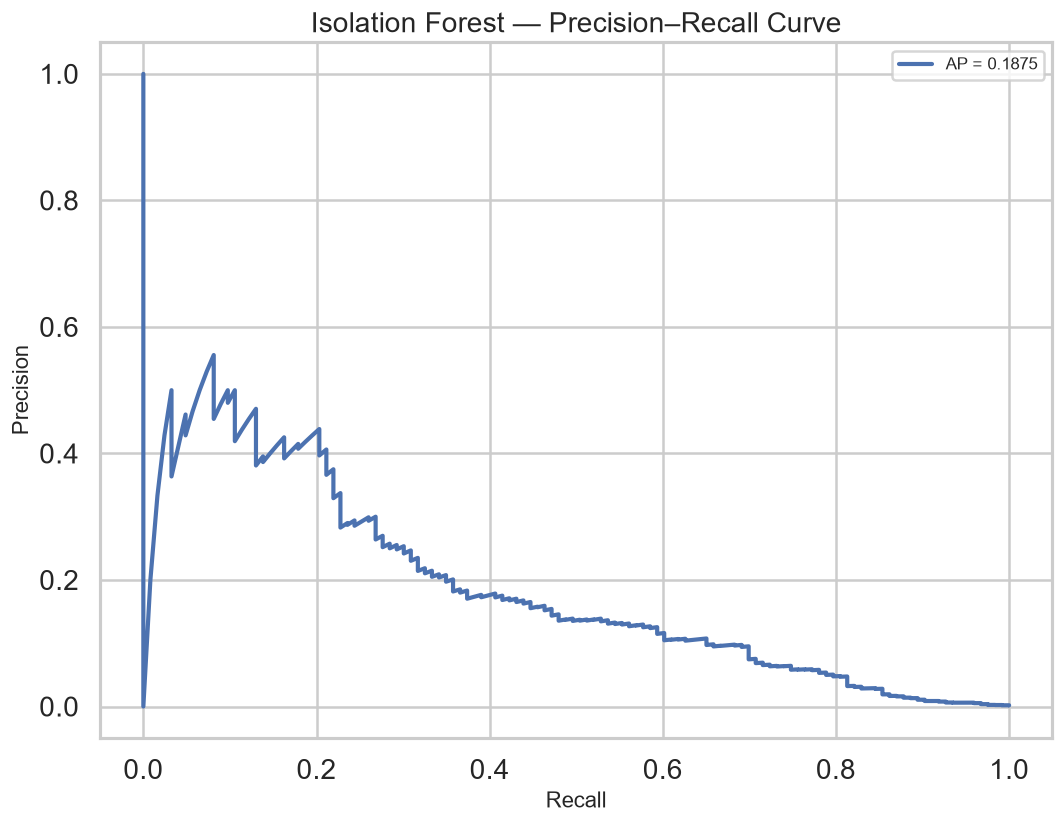

In [7]:
# PR curve — recruiter-friendly evaluation under severe class imbalance.
precision, recall, thresholds = precision_recall_curve(y_test, test_scores)
fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(recall, precision, linewidth=2.5, label=f"AP = {metrics.pr_auc:.4f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Isolation Forest — Precision–Recall Curve")
ax.legend()
fig.tight_layout()
save_figure(fig, FIG_DIR / "isolation_forest_pr_curve")
plt.show()